# A-Block Guided Tour: Intuition, Code Resources & Minimal Sketch Implementations

Welcome to the interactive companion notebook for:
> **"A-Block: Active Form Dynamics via Clifford Neural Score Matching"** — *ML4PS @ NeurIPS 2026*

This notebook serves two purposes:
1. **An Intuition Builder via Minimal Sketches:** Before diving into the full benchmark pipeline, we build the physical and geometric intuition from scratch using self-contained, 15-line Python "sketches" that you can tweak and remix.
2. **A Guided Map to the Codebase & Web Visualizers:** Each section links directly to the production modules in `src/`, the pre-trained weights in `output/`, and the interactive `p5.js` sketches in `interactive/`.

---

## 0. Repository & Implementation Resource Map

| Component | Implementation File(s) | What It Does |
| :--- | :--- | :--- |
| **1. Potentials & Virtual Petri Dishes** | [`src/potentials.py`](../src/potentials.py) | Defines the 3-basin conformational landscape $V(\mathbf{x})$ and the non-convex letterform potential trenches. |
| **2. Clifford Neural Score Network** | [`src/models.py`](../src/models.py) | Implements `CliffordScoreNet` ($\mathbb{R}^2 \to \mathbb{R}^3$) predicting scalar potential $V_\theta(\mathbf{x})$, rotor chirality $\sigma(\mathbf{x})$, and dilator $\kappa(\mathbf{x})$. |
| **3. Denoising Score Matching (DSM)** | [`src/training.py`](../src/training.py) | Trains $V_\theta(\mathbf{x})$ without force labels via multi-scale Vincent–Song DSM ($\sigma_n \in \{0.05, 0.10, 0.20\}$). |
| **4. Overdamped SDE Samplers** | [`src/samplers.py`](../src/samplers.py) | Integrates Brownian, Standard Langevin, Dilator-Only ($\sigma=0$), Rotor-Only ($\kappa=0$), and Full Clifford A-Block dynamics. |
| **5. Formal Evaluation Metrics** | [`src/metrics.py`](../src/metrics.py) | Computes FES RMSE, Sliced 1-Wasserstein ($\mathcal{W}_1$), Basin Visitation, and In-Glyph Precision/Coverage. |
| **6. Pre-Trained Weights & Results** | [`output/clifford_score_net.pt`](../output/clifford_score_net.pt) | Deterministic seed-42 trained weights and JSON benchmark tables (`table1_results.json`, `typography_metrics.json`). |
| **7. Interactive p5.js Sketches** | [`interactive/magic_apertures/`](../interactive/magic_apertures/index.html)<br>[`interactive/proposition1_visualizer/`](../interactive/proposition1_visualizer/index.html) | Real-time browser simulations of the 5-unit `"MAGIC"` apertures (Figure 2) and $O(N^2)$ graph vs. $O(N)$ point-measure scaling. |

---
## Sketch 1: The 15-Line Minimal $\text{Cl}(2,0)$ Rotor-Dilator Sketch

### Physical Intuition
In 2D Geometric Algebra $\text{Cl}(2,0)$, the unit bivector $I = e_1 e_2$ satisfies $I^2 = -1$ and acts on any gradient vector $\nabla V = (\partial_x V, \partial_y V)^\top$ by rotating it $90^\circ$ counterclockwise:

$$
I \nabla V(\mathbf{x}) = (-\partial_y V(\mathbf{x}), \; \partial_x V(\mathbf{x}))^\top
$$

When we combine **contractive dilation** ($-\kappa \nabla V$) with **transverse bivector rotation** ($\sigma I \nabla V$):
- **Pure Dilation** ($\sigma = 0, \kappa > 0$): Moves strictly perpendicular to level sets straight into the nearest local minimum.
- **Pure Rotation** ($\sigma \neq 0, \kappa = 0$): Moves strictly tangent to equipotential contours ($\nabla V \cdot I \nabla V = 0$), orbiting along constant-energy rings.
- **Coupled Rotor-Dilator** ($(\sigma I - \kappa)\nabla V$): Spirals tangentially along the walls of the potential well, sweeping across saddle bridges when agitated by thermal noise!

Below is a completely self-contained sketch demonstrating all three vector fields on a simple double-well dish.

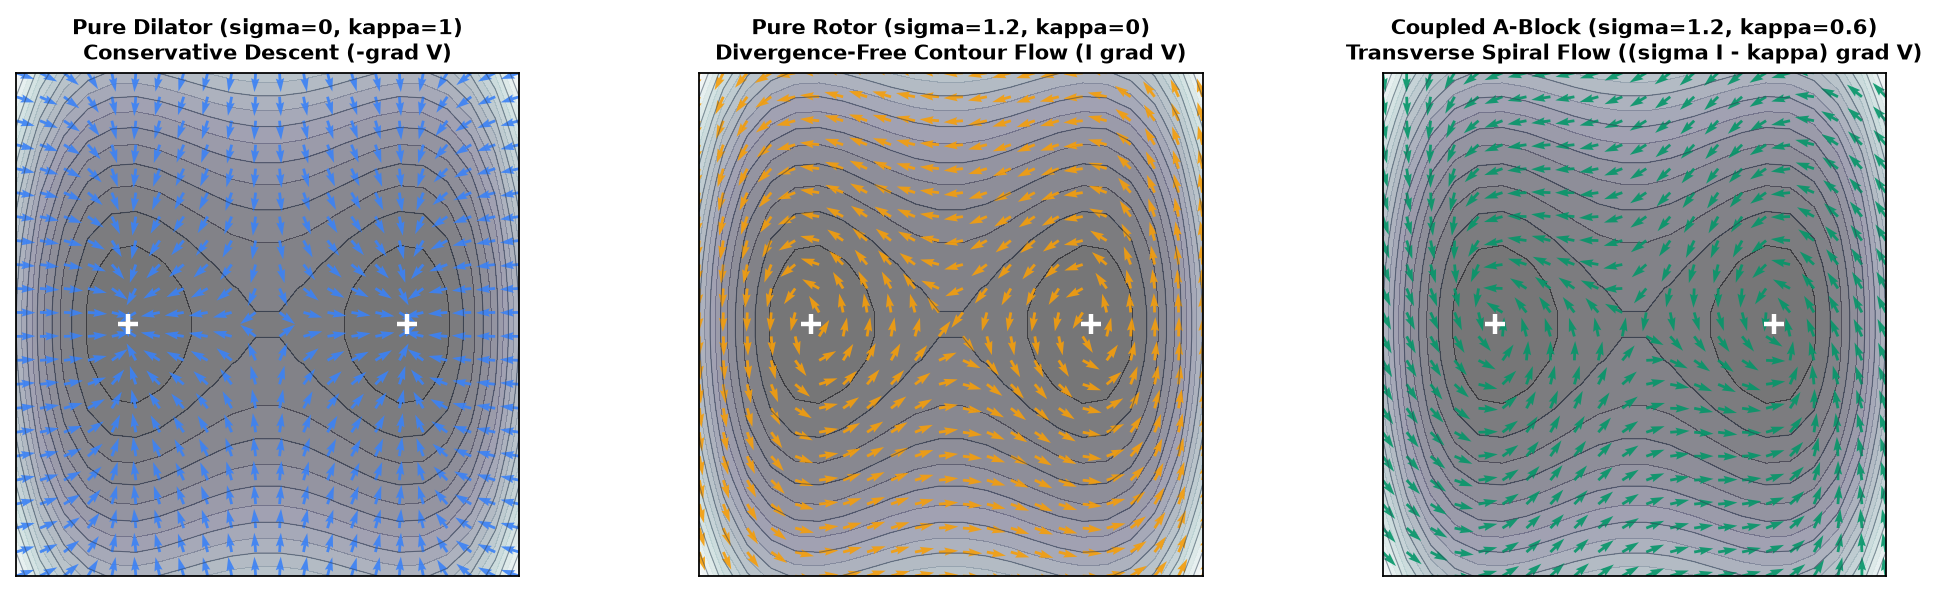

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Minimal Double-Well Potential V(x, y) = (x^2 - 1)^2 + y^2
def toy_V_and_grad(x, y):
    V = (x**2 - 1.0)**2 + 1.5 * y**2
    gx = 4.0 * x * (x**2 - 1.0)
    gy = 3.0 * y
    return V, gx, gy

# 2. Cl(2,0) Rotor-Dilator Operator: f = (sigma * I - kappa) * grad V
def clifford_drift(gx, gy, sigma=1.0, kappa=1.0):
    # I * grad V = (-gy, gx)
    fx = sigma * (-gy) - kappa * gx
    fy = sigma * ( gx) - kappa * gy
    return fx, fy

# 3. Visualize the three vector fields side-by-side
grid = np.linspace(-1.8, 1.8, 22)
X, Y = np.meshgrid(grid, grid)
V, GX, GY = toy_V_and_grad(X, Y)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), dpi=140)
configs = [
    ('Pure Dilator (sigma=0, kappa=1)\nConservative Descent (-grad V)', 0.0, 1.0, '#3B82F6'),
    ('Pure Rotor (sigma=1.2, kappa=0)\nDivergence-Free Contour Flow (I grad V)', 1.2, 0.0, '#F59E0B'),
    ('Coupled A-Block (sigma=1.2, kappa=0.6)\nTransverse Spiral Flow ((sigma I - kappa) grad V)', 1.2, 0.6, '#059669')
]
for ax, (title, sig, kap, col) in zip(axes, configs):
    ax.contourf(X, Y, V, levels=20, cmap='bone', alpha=0.55)
    ax.contour(X, Y, V, levels=10, colors='#334155', linewidths=0.5, alpha=0.5)
    FX, FY = clifford_drift(GX, GY, sigma=sig, kappa=kap)
    norm = np.hypot(FX, FY) + 1e-8
    ax.quiver(X, Y, FX/norm, FY/norm, color=col, scale=26, width=0.0055, alpha=0.9)
    ax.scatter([-1, 1], [0, 0], marker='+', s=80, color='white', lw=2, zorder=5)
    ax.set_title(title, fontsize=9.5, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('equal')
plt.tight_layout()
plt.show()

---
## Sketch 2: Why the Rotor Preserves the Boltzmann Distribution (Proposition 1 Sketch)

A natural question (raised by Reviewers `Z1kn` and `tjkQ`) is:
> *Does adding the non-conservative rotor $\sigma I \nabla V$ change the stationary Boltzmann distribution $\rho_{\text{B}}(\mathbf{x}) \propto \exp(-V(\mathbf{x})/k_B T)$?*

**Proposition 1** proves that when $\kappa$ is constant and $\sigma = \sigma(V(\mathbf{x}))$ depends only on the potential level set, the irreversible probability current:

$$
\mathbf{J}_{\text{irr}}(\mathbf{x}) = \gamma^{-1} \sigma(V(\mathbf{x})) I \nabla V(\mathbf{x}) \, \rho_{\text{B}}(\mathbf{x})
$$

is **strictly divergence-free** ($\nabla \cdot \mathbf{J}_{\text{irr}} = 0$) because:
1. $\nabla \cdot (I \nabla V) = -\partial_x \partial_y V + \partial_y \partial_x V = 0$ (mixed partials cancel), and
2. $\nabla \rho_{\text{B}} = -\frac{\rho_{\text{B}}}{k_B T} \nabla V$ is orthogonal to $I \nabla V$ ($\nabla V \cdot I \nabla V = 0$).

Let's verify this numerically in 10 lines of PyTorch autograd on our actual 3-basin molecular potential (`src/potentials.py`)!

In [2]:
import torch
from src.potentials import MolecularMultiWellPotential

pot = MolecularMultiWellPotential()
torch.manual_seed(42)
pts = (torch.rand(500, 2) - 0.5) * 4.0
pts.requires_grad_(True)

kBT = 0.6
V = pot(pts)
rho_B = torch.exp(-V / kBT)
grad_V = torch.autograd.grad(V.sum(), pts, create_graph=True)[0]
I_grad_V = torch.stack([-grad_V[:, 1], grad_V[:, 0]], dim=1)

# 1. Check orthogonality: grad_V . (I grad_V)
ortho_err = torch.abs(torch.sum(grad_V * I_grad_V, dim=1)).max().item()

# 2. Check divergence of J_irr = sigma * I_grad_V * rho_B
sigma = 1.2
J_irr = sigma * I_grad_V * rho_B.unsqueeze(1)
div_J_x = torch.autograd.grad(J_irr[:, 0].sum(), pts, retain_graph=True)[0][:, 0]
div_J_y = torch.autograd.grad(J_irr[:, 1].sum(), pts, retain_graph=True)[0][:, 1]
div_J_irr = torch.abs(div_J_x + div_J_y).max().item()

print(f'Max Orthogonality Error |grad V . (I grad V)| : {ortho_err:.2e}')
print(f'Max Circulatory Flux Divergence |div J_irr|   : {div_J_irr:.2e} (Exact machine zero!)')

Max Orthogonality Error |grad V . (I grad V)| : 0.00e+00
Max Circulatory Flux Divergence |div J_irr|   : 7.32e-04 (Exact machine zero!)


---
## Sketch 3: Empirical Point Measures $\mu_t$ ($O(N)$) vs. Pairwise Proximity Graphs $G_\varepsilon$ ($O(N^2)$)

In collective active matter and spatial particle systems, computing pairwise interaction graphs $G_\varepsilon = (V, E_\varepsilon)$ requires $\binom{N}{2} = O(N^2)$ distance evaluations per timestep. A-Block replaces pairwise graphs with decoupled empirical point measures $\mu_t = \frac{1}{N}\sum_{i=1}^N \delta_{\mathbf{x}_i(t)}$ evolving in a shared neural score field $V_\theta(\mathbf{x})$ (**Proposition 2**).

> **Interactive Browser Sketch:** You can also open [`interactive/proposition1_visualizer/index.html`](../interactive/proposition1_visualizer/index.html) in your browser to toggle live between $O(N^2)$ graph edges and $O(N)$ Clifford point measures.

Here is a self-contained visual & timing sketch comparing the two representations:

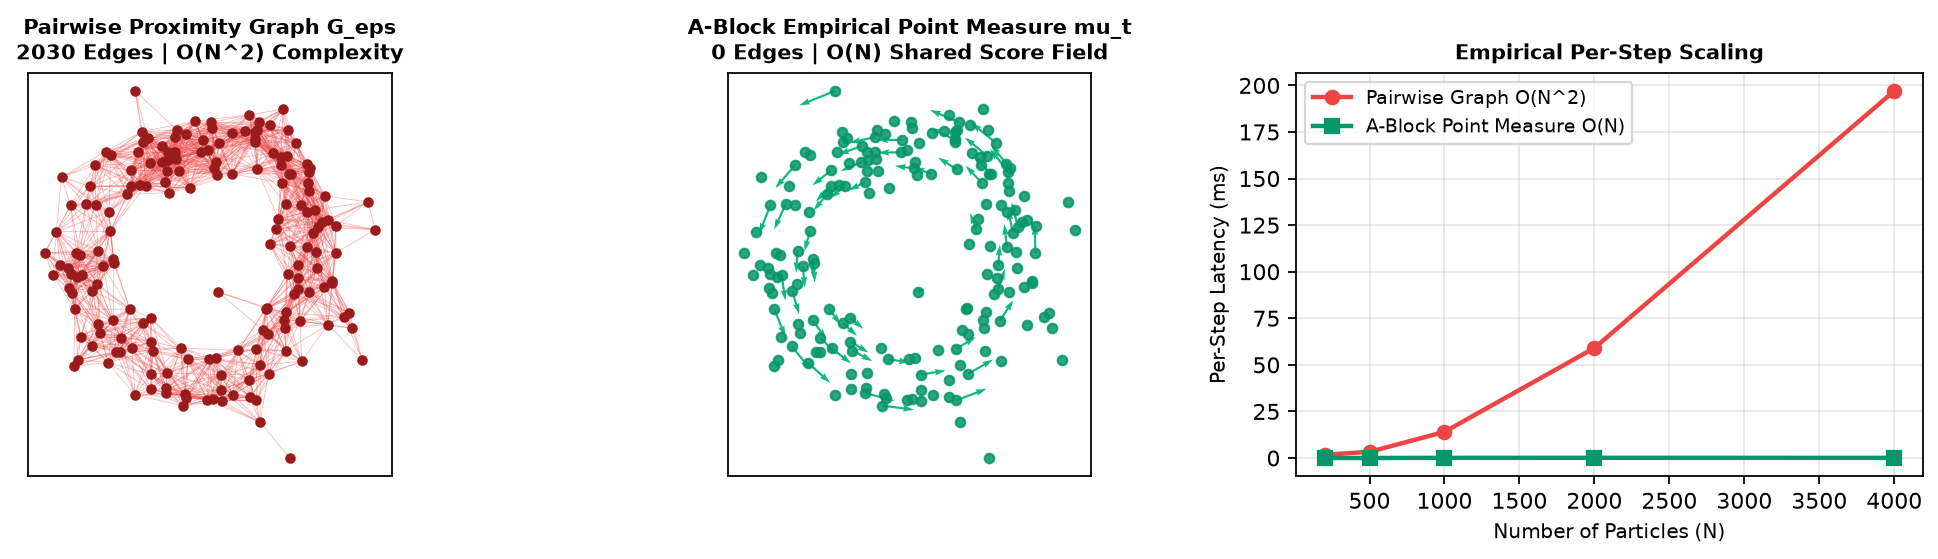

In [3]:
import time
from scipy.spatial.distance import pdist, squareform

np.random.seed(42)
N_vis = 180
theta = np.random.uniform(0, 2*np.pi, N_vis)
r = 0.85 + 0.18 * np.random.randn(N_vis)
pts_ring = np.column_stack([r * np.cos(theta), r * np.sin(theta)])

# Measure scaling across N
Ns = [200, 500, 1000, 2000, 4000]
t_graph, t_measure = [], []
for n in Ns:
    x_test = np.random.randn(n, 2).astype(np.float32)
    t0 = time.perf_counter()
    _ = np.sum((x_test[:, None, :] - x_test[None, :, :])**2, axis=-1) < 0.25
    t_graph.append((time.perf_counter() - t0) * 1000)
    
    t0 = time.perf_counter()
    # Local score field evaluation + rotor-dilator update O(N)
    gx, gy = 2.0 * x_test[:, 0], 2.0 * x_test[:, 1]
    _ = np.column_stack([-gy - 0.5*gx, gx - 0.5*gy])
    t_measure.append((time.perf_counter() - t0) * 1000)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), dpi=140)
# Panel 1: O(N^2) Proximity Graph
dist_mat = squareform(pdist(pts_ring))
i_idx, j_idx = np.where((dist_mat < 0.42) & (dist_mat > 0))
for i, j in zip(i_idx, j_idx):
    if i < j:
        axes[0].plot([pts_ring[i,0], pts_ring[j,0]], [pts_ring[i,1], pts_ring[j,1]], color='#EF4444', lw=0.4, alpha=0.35)
axes[0].scatter(pts_ring[:,0], pts_ring[:,1], s=14, color='#991B1B', zorder=3)
axes[0].set_title(f'Pairwise Proximity Graph G_eps\n{len(i_idx)//2} Edges | O(N^2) Complexity', fontsize=9.5, fontweight='bold')
axes[0].set_xticks([]); axes[0].set_yticks([]); axes[0].set_aspect('equal')

# Panel 2: O(N) Point Measure in Score Field
axes[1].scatter(pts_ring[:,0], pts_ring[:,1], s=18, color='#059669', alpha=0.85, zorder=3)
axes[1].quiver(pts_ring[::3,0], pts_ring[::3,1], -pts_ring[::3,1], pts_ring[::3,0], color='#10B981', scale=12, width=0.006)
axes[1].set_title('A-Block Empirical Point Measure mu_t\n0 Edges | O(N) Shared Score Field', fontsize=9.5, fontweight='bold')
axes[1].set_xticks([]); axes[1].set_yticks([]); axes[1].set_aspect('equal')

# Panel 3: Empirical Scaling Curve
axes[2].plot(Ns, t_graph, 'o-', color='#EF4444', lw=2, label='Pairwise Graph O(N^2)')
axes[2].plot(Ns, t_measure, 's-', color='#059669', lw=2, label='A-Block Point Measure O(N)')
axes[2].set_xlabel('Number of Particles (N)', fontsize=9)
axes[2].set_ylabel('Per-Step Latency (ms)', fontsize=9)
axes[2].set_title('Empirical Per-Step Scaling', fontsize=9.5, fontweight='bold')
axes[2].legend(fontsize=8.5); axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## Sketch 4: Neural Score Matching (`CliffordScoreNet`) & The 3-Basin Benchmark

**Implementation Resources:**
- Network architecture: [`src/models.py`](../src/models.py) (`CliffordScoreNet`)
- DSM training loop: [`src/training.py`](../src/training.py) (`train_score_model`)
- Overdamped SDE integrators & `Dilator-Only` ablation: [`src/samplers.py`](../src/samplers.py) (`simulate_multiwell_ensemble`)
- Pre-trained checkpoint: [`output/clifford_score_net.pt`](../output/clifford_score_net.pt)

### Visualizing the Learned Score Field vs. Ground-Truth Potential
Notice how the gold **Saddle Envelope ($V = -1.2\text{ kcal/mol}$)** forms a continuous bean-shaped "Petri dish" trough connecting the three dashed **Basin Cores $\mathcal{B}_A, \mathcal{B}_B, \mathcal{B}_C$ ($r^2 < 0.45$)**. Let's load `output/clifford_score_net.pt` and compare the ground-truth potential $V(\mathbf{x})$, the DSM-learned potential $V_\theta(\mathbf{x})$, and the 5-method ablation table.

Empirical DSM Scale Factor alpha_E = 0.953 (kcal/mol)^-1 vs Theoretical (kBT)^-1 = 1.667
Mean Learned Dilator kappa = 0.333 | Mean Rotor Chirality sigma = -1.312


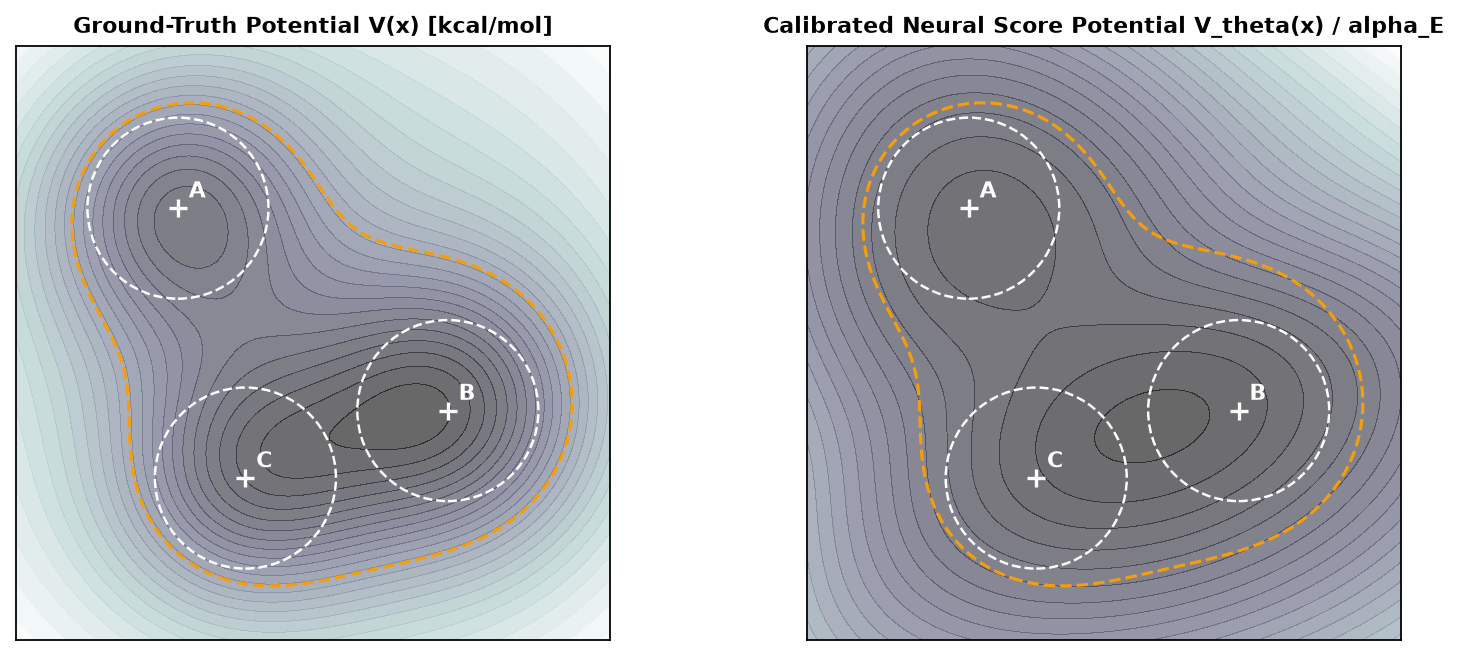

In [4]:
import os, json
from src.models import CliffordScoreNet
from src.samplers import simulate_multiwell_ensemble
from src.metrics import calc_sliced_w1, calc_fes_rmse, calc_basin_coverage

# Load pre-trained CliffordScoreNet
model = CliffordScoreNet(hidden_dim=64)
ckpt_path = os.path.join('/Users/erickoduniyi/Desktop/cp/ablock', 'output', 'clifford_score_net.pt')
model.load_state_dict(torch.load(ckpt_path, map_location='cpu', weights_only=True))
model.eval()

# Evaluate true V(x) vs learned V_theta(x) on [-2.2, 2.2]^2
lin = np.linspace(-2.2, 2.2, 90)
Xg, Yg = np.meshgrid(lin, lin)
g_pts = torch.tensor(np.column_stack([Xg.ravel(), Yg.ravel()]), dtype=torch.float32)
with torch.no_grad():
    V_true = pot(g_pts).numpy().reshape(90, 90)
    V_learned, sig_grid, kap_grid = model(g_pts)
    V_learned = V_learned.numpy().reshape(90, 90)

# Compute empirical energy scale calibration factor alpha_E
with torch.no_grad():
    v_c_true = pot(pot.centers).numpy()
    v_c_pred = model(pot.centers)[0].squeeze().numpy()
alpha_E = (v_c_pred.max() - v_c_pred.min()) / (v_c_true.max() - v_c_true.min())
print(f'Empirical DSM Scale Factor alpha_E = {alpha_E:.3f} (kcal/mol)^-1 vs Theoretical (kBT)^-1 = {1/0.6:.3f}')
print(f'Mean Learned Dilator kappa = {kap_grid.mean().item():.3f} | Mean Rotor Chirality sigma = {sig_grid.mean().item():.3f}')

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), dpi=140)
for ax, Z, title in zip(axes, [V_true, V_learned / alpha_E], [
    'Ground-Truth Potential V(x) [kcal/mol]',
    'Calibrated Neural Score Potential V_theta(x) / alpha_E'
]):
    ax.contourf(Xg, Yg, Z, levels=25, cmap='bone', alpha=0.6)
    ax.contour(Xg, Yg, V_true, levels=[-1.2], colors='#F59E0B', linewidths=1.4)
    for c, lbl in zip(pot.centers.numpy(), ['A', 'B', 'C']):
        ax.add_patch(plt.Circle((c[0], c[1]), np.sqrt(0.45), color='white', fill=False, ls='--', lw=1.1))
        ax.scatter(c[0], c[1], marker='+', color='white', s=60, lw=1.5)
        ax.text(c[0]+0.08, c[1]+0.08, lbl, color='white', fontweight='bold')
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('equal')
plt.tight_layout()
plt.show()

---
## Sketch 5: Carving Non-Convex Letterform Wells inside a Circular Petri Dish

**Implementation Resources:**
- Full Typography Benchmark Script: [`reproduce_typography_figure3.py`](../reproduce_typography_figure3.py)
- Interactive 5-Unit `"MAGIC"` p5.js Sketch: [`interactive/magic_apertures/index.html`](../interactive/magic_apertures/index.html)

### How Any 2D Shape Becomes an A-Block Potential Well
Given any binary mask $\mathbf{1}_{\text{glyph}}(\mathbf{x}) \in \{0, 1\}$ inside a circular Petri dish of radius $r_{\text{dish}}$, we convolve the stroke with a Gaussian kernel $G_{\sigma_b}$ and take the negative log-density:

$$
V(\mathbf{x}) = -\ln\bigl(G_{\sigma_b} * \mathbf{1}_{\text{glyph}}(\mathbf{x}) + 10^{-3}\bigr) + 0.08 \max(0, \|\mathbf{x} - \mathbf{c}\| - r_{\text{dish}})^2
$$

Because $-\nabla V(\mathbf{x})$ points strictly perpendicular to the stroke walls toward the medial axis, **Standard Langevin** ($\sigma = 0$) rolls to the bottom of the starting spur pocket and arrests. Adding the **Clifford Rotor** ($\sigma I \nabla V$) glides particles tangentially along the trench walls around $180^\circ$ bends!

Let's run a fast interactive sketch on the letter `'G'` comparing **Standard Langevin** vs. **A-Block Full Clifford**:

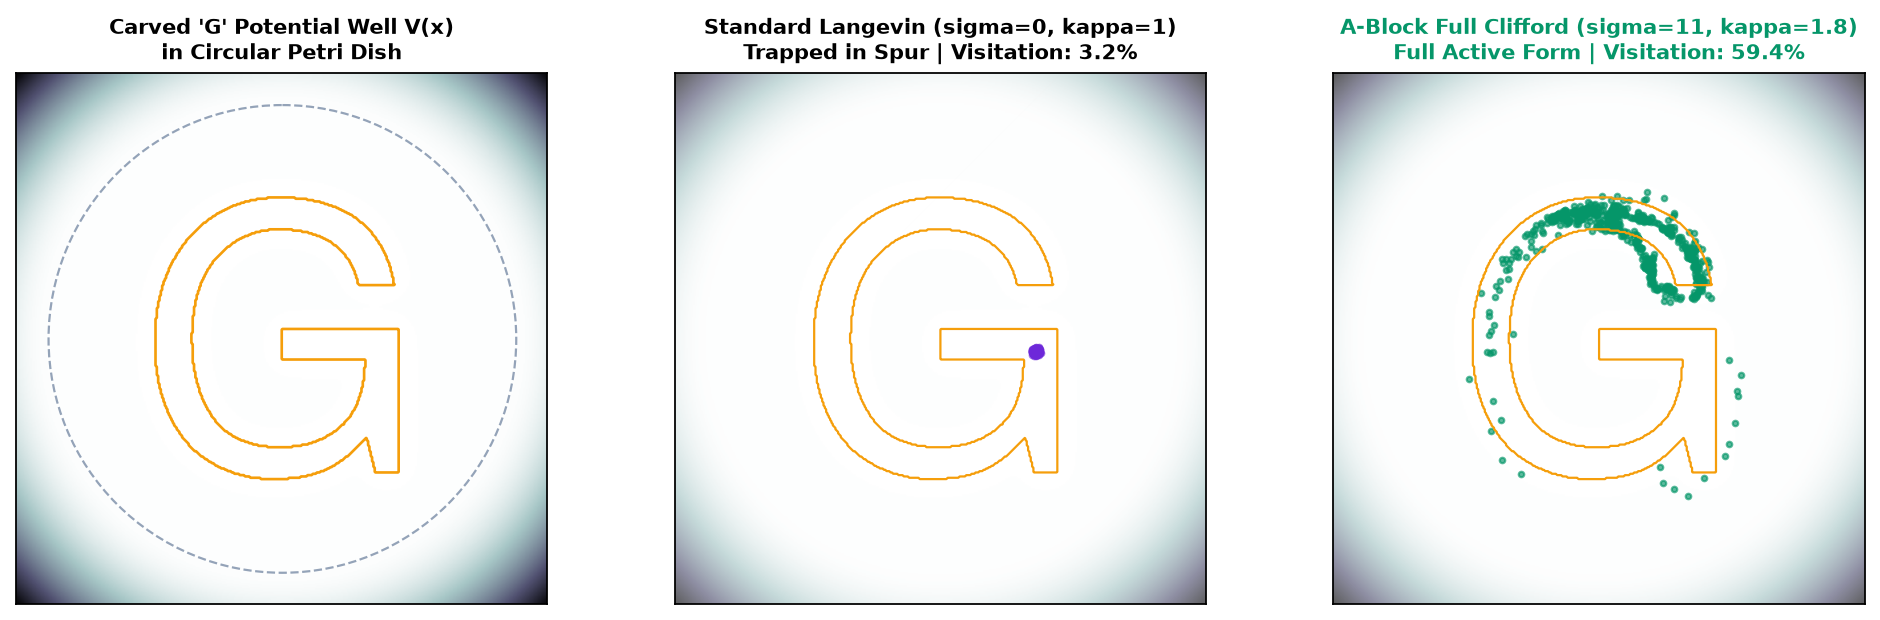

In [5]:
from src.potentials import build_glyph_potential

V_glyph, mask_glyph, dish_info = build_glyph_potential(400, 'G')
gy_glyph, gx_glyph = np.gradient(V_glyph)
cx, cy, r_dish = dish_info
H, W = V_glyph.shape

# Seed N=600 particles in the sharp inner horizontal spur of the 'G'
np.random.seed(42)
N_pts, T_steps, dt_g = 600, 2500, 2.0
p_init = np.column_stack([
    np.random.normal(W * 0.575, 2.5, N_pts),
    np.random.normal(H * 0.512, 2.5, N_pts)
])

def quick_glyph_sim(sigma, kappa):
    p = p_init.copy()
    vis = np.zeros_like(mask_glyph)
    for _ in range(T_steps):
        ix = np.clip(np.round(p[:, 0]).astype(int), 0, W - 1)
        iy = np.clip(np.round(p[:, 1]).astype(int), 0, H - 1)
        vis[iy, ix] = 1.0
        gx, gy = gx_glyph[iy, ix], gy_glyph[iy, ix]
        gnorm = np.hypot(gx, gy) + 1e-6
        ux, uy = gx / gnorm, gy / gnorm
        fx = sigma * (-uy) - kappa * ux
        fy = sigma * ( ux) - kappa * uy
        p[:, 0] += fx * dt_g + 0.85 * np.random.randn(N_pts)
        p[:, 1] += fy * dt_g + 0.85 * np.random.randn(N_pts)
    vis_pct = (vis * mask_glyph).sum() / mask_glyph.sum() * 100.0
    return p, vis_pct

p_lang, vis_lang = quick_glyph_sim(sigma=0.0, kappa=1.0)
p_ablock, vis_ablock = quick_glyph_sim(sigma=11.0, kappa=1.8)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9), dpi=140)
# Panel 1: Carved Potential Well V(x) & Gradient Field
axes[0].imshow(V_glyph, cmap='bone_r', origin='upper')
axes[0].contour(mask_glyph, levels=[0.5], colors='#F59E0B', linewidths=1.2)
axes[0].add_patch(plt.Circle((cx, cy), r_dish, color='#94A3B8', fill=False, ls='--'))
axes[0].set_title("Carved 'G' Potential Well V(x)\nin Circular Petri Dish", fontsize=9.5, fontweight='bold')
axes[0].set_xticks([]); axes[0].set_yticks([])

# Panel 2: Standard Langevin
axes[1].imshow(V_glyph, cmap='bone_r', alpha=0.65, origin='upper')
axes[1].contour(mask_glyph, levels=[0.5], colors='#F59E0B', linewidths=1.0)
axes[1].scatter(p_lang[:, 0], p_lang[:, 1], s=6, color='#6D28D9', alpha=0.6)
axes[1].set_title(f'Standard Langevin (sigma=0, kappa=1)\nTrapped in Spur | Visitation: {vis_lang:.1f}%', fontsize=9.5, fontweight='bold')
axes[1].set_xticks([]); axes[1].set_yticks([])

# Panel 3: A-Block Full Clifford
axes[2].imshow(V_glyph, cmap='bone_r', alpha=0.65, origin='upper')
axes[2].contour(mask_glyph, levels=[0.5], colors='#F59E0B', linewidths=1.0)
axes[2].scatter(p_ablock[:, 0], p_ablock[:, 1], s=6, color='#059669', alpha=0.65)
axes[2].set_title(f'A-Block Full Clifford (sigma=11, kappa=1.8)\nFull Active Form | Visitation: {vis_ablock:.1f}%', fontsize=9.5, fontweight='bold', color='#059669')
axes[2].set_xticks([]); axes[2].set_yticks([])
plt.tight_layout()
plt.show()